## List of Lists Representation
binary trees

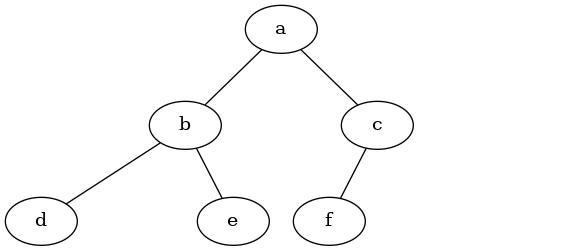

In [1]:
my_tree = [
    "a",  # root
        ["b",  # left subtree
            ["d", [], []],
            ["e", [], []]
        ],
        ["c",  # right subtree
            ["f", [], []],
            []
        ],
    ]


In [2]:
my_tree[1][2]

['e', [], []]

In [3]:
def make_binary_tree(root):
    """
    Creates a new binary tree node.
    Represented as a list: [root_value, left_child_list, right_child_list]
    """
    return [root, [], []]


def insert_left(root, new_child):
    """
    Inserts a new node as the left child of the given root.
    If a left child already exists, it is pushed down as the left child of the new node.
    """
    # Remove the existing left child (at index 1)
    old_child = root.pop(1) # # This removes index 1 first! (Length drops to 2)
    
    # If the old child was not empty, preserve it by nesting it inside the new child
    if len(old_child) > 1:
        root.insert(1, [new_child, old_child, []])
    else:
        # Otherwise, simply insert the new child node with empty subtrees
        root.insert(1, [new_child, [], []])
    return root


def insert_right(root, new_child):
    """
    Inserts a new node as the right child of the given root.
    If a right child already exists, it is pushed down as the right child of the new node.
    """
    # Remove the existing right child (at index 2)
    old_child = root.pop(2)
    
    # If the old child was not empty, preserve it by nesting it inside the new child
    if len(old_child) > 1:
        root.insert(2, [new_child, [], old_child])
    else:
        # Otherwise, simply insert the new child node with empty subtrees
        root.insert(2, [new_child, [], []])
    return root


def get_root_val(root):
    """Returns the value stored in the root node (index 0)."""
    return root[0]


def set_root_val(root, new_value):
    """Modifies the value stored in the root node (index 0)."""
    root[0] = new_value


def get_left_child(root):
    """Returns the subtree representing the left child (index 1)."""
    return root[1]


def get_right_child(root):
    """Returns the subtree representing the right child (index 2)."""
    return root[2]


# --- Test Execution ---

# 1. Create a tree with a root value of 3: [3, [], []]
a_tree = make_binary_tree(3)

# 2. Insert 4 to the left: [3, [4, [],[]], []]
insert_left(a_tree, 4)

# 3. Insert 5 to the left. The existing node 4 gets pushed down: [3, [5, [4, [],[]], []], []]
insert_left(a_tree, 5)

# 4. Insert 6 to the right: [3, [5, [4, [],[]], []], [6, [], []]]
insert_right(a_tree, 6)

# 5. Insert 7 to the right. The existing node 6 gets pushed down: [3, [5, [4, [],[]], []], [7, [], [6, [],[]]]]
insert_right(a_tree, 7)

# Fetch the left child subtree of the main root
left_child = get_left_child(a_tree)
print("Left child subtree:", left_child)  # Output: [5, [4, [], []], []]

# Modify the root value of the left child subtree from 5 to 9
set_root_val(left_child, 9)
print("Tree after modifying left child root value:", a_tree)

# Insert 11 as the left child of the left child subtree. Node 4 gets pushed down.
insert_left(left_child, 11)
print("Tree after inserting 11:", a_tree)

# Fetch the right child of the right child of the main tree
print("Right-Right child:", get_right_child(get_right_child(a_tree)))  # Output: [6, [], []]


Left child subtree: [5, [4, [], []], []]
Tree after modifying left child root value: [3, [9, [4, [], []], []], [7, [], [6, [], []]]]
Tree after inserting 11: [3, [9, [11, [4, [], []], []], []], [7, [], [6, [], []]]]
Right-Right child: [6, [], []]


In [4]:
ll = [1,2,3]
ll.insert(1,7)
ll

[1, 7, 2, 3]

## Nodes and References

In [5]:
class BinaryTree:
    def __init__(self, root):
        self.key = root
        self.left_child = None
        self.right_child = None
        
    def insert_left(self,new_node):
        if self.left_child == None:
            self.left_child = BinaryTree(new_node)
        else:
            t = BinaryTree(new_node)
            t.left_child = self.left_child
            self.left_child = t

    def insert_right(self,new_node):
        if self.right_child == None:
            self.right_child = BinaryTree(new_node)
        else:
            t = BinaryTree(new_node)
            t.right_child = self.right_child
            self.right_child = t

    def get_right_child(self):
        return self.right_child
    def get_left_child(self):
        return self.left_child
    def set_root_val(self,obj):
        self.key = obj
    def get_root_val(self):
        return self.key

# Completed implementation of a stack ADT
class Stack:
    def __init__(self):
        self.items = []
    def is_empty(self):
        return self.items == [] # returns true if empty
    def push(self, item):
        self.items.append(item)
    def pop(self):
        return self.items.pop()
        #if len(self.items) != 0:
         #   return self.items.pop()
        #else:
         #   return 'XXX'
    def peek(self):
        return self.items[len(self.items)-1]
    def size(self):
        return len(self.items)
    def head (self):
       return self.items[:5]
    def tail (self): # but tail does not show it in reverse order
       return self.items[-5:]


In [6]:
r = BinaryTree('a')
print(r.get_root_val())
print(r.get_left_child())
r.insert_left('b')
print(r.get_left_child())
print(r.get_left_child().get_root_val())
r.insert_right('c')
print(r.get_right_child())
print(r.get_right_child().get_root_val())
r.get_right_child().set_root_val('hello')
print(r.get_right_child().get_root_val())

a
None
b
c
hello


In [7]:
# we do an exercise object called ex
ex = BinaryTree('a')
ex.insert_left("b")
ex.get_left_child().get_root_val()
ex.get_left_child().insert_right('d')
ex.get_left_child().get_right_child().get_root_val()
ex.insert_right('f')
print(ex.get_right_child().get_root_val())
ex.insert_right('c')
print(ex.get_right_child().get_root_val(), ex.get_right_child().get_right_child().get_root_val())
ex.get_right_child().insert_left('e')
ex.get_right_child().get_left_child().get_root_val()

f
c f


'e'

### Parse Tree

In [8]:
import operator

# ==========================================
# 1. Binary Tree Implementation
# ==========================================
class BinaryTree:
    def __init__(self, root):
        self.key = root
        self.left_child = None
        self.right_child = None
        
    def insert_left(self, new_node):
        if self.left_child == None:
            self.left_child = BinaryTree(new_node)
        else:
            t = BinaryTree(new_node)
            t.left_child = self.left_child
            self.left_child = t

    def insert_right(self, new_node):
        if self.right_child == None:
            self.right_child = BinaryTree(new_node)
        else:
            t = BinaryTree(new_node)
            t.right_child = self.right_child
            self.right_child = t

    def get_right_child(self):
        return self.right_child
        
    def get_left_child(self):
        return self.left_child
        
    def set_root_val(self, obj):
        self.key = obj
        
    def get_root_val(self):
        return self.key

    # Prints a postorder string representation of the tree nodes
    def postorder(self):
        if self.left_child:
            self.left_child.postorder()
        if self.right_child:
            self.right_child.postorder()
        print(self.key, end=" ")


# ==========================================
# 2. Stack Abstract Data Type
# ==========================================
class Stack:
    def __init__(self):
        self.items = []
        
    def is_empty(self):
        return self.items == []
        
    def push(self, item):
        self.items.append(item)
        
    def pop(self):
        return self.items.pop()
        
    def peek(self):
        return self.items[len(self.items)-1]
        
    def size(self):
        return len(self.items)


# ==========================================
# 3. Core Requirements Functions
# ==========================================

# Requirement 1: Build the Parse Tree from tokens
def build_parse_tree(fp_expr):
    fp_list = fp_expr.split()
    p_stack = Stack()
    expr_tree = BinaryTree("")
    p_stack.push(expr_tree)
    current_tree = expr_tree

    for i in fp_list:
        if i == "(":
            # Rule 1: Add a new node as left child and descend
            current_tree.insert_left("")
            p_stack.push(current_tree)
            current_tree = current_tree.get_left_child()
            
        elif i in ["+", "-", "*", "/"]:
            # Rule 2: Set root value to operator, add right child and descend
            current_tree.set_root_val(i) # Fixed original bug (was .root)
            current_tree.insert_right("")
            p_stack.push(current_tree)
            current_tree = current_tree.get_right_child()
            
        elif i.isdigit():
            # Rule 3: Set root value to number, return to parent
            current_tree.set_root_val(int(i))
            parent = p_stack.pop()
            current_tree = parent
            
        elif i == ")":
            # Rule 4: Go up to parent node
            current_tree = p_stack.pop()
            
        else:
            raise ValueError(f"Unknown operator '{i}'")

    return expr_tree


# Requirement 2: Evaluate the mathematical expression stored in the tree
def evaluate(parse_tree):
    # Mapping operators to mathematical actions
    opers = {'+': operator.add, '-': operator.sub, '*': operator.mul, '/': operator.truediv}

    left_c = parse_tree.get_left_child()
    right_c = parse_tree.get_right_child()

    # Base Case: If it's a leaf node (no children), it's a number. Return it.
    if left_c is None and right_c is None:
        return parse_tree.get_root_val()
    else:
        # Recursive step: Evaluate the left and right subtrees
        left_val = evaluate(left_c)
        right_val = evaluate(right_c)
        fn = opers[parse_tree.get_root_val()]
        return fn(left_val, right_val)


# Requirement 3: Recover the original parenthesized expression from the tree
def recover_expr(parse_tree):
    left_c = parse_tree.get_left_child()
    right_c = parse_tree.get_right_child()

    # Base Case: It's a single operand leaf node
    if left_c is None and right_c is None:
        return str(parse_tree.get_root_val())
    
    # Recursive step: Re-wrap operations inside parenthesis
    left_side = recover_expr(left_c)
    right_side = recover_expr(right_c)
    return f"({left_side} {parse_tree.get_root_val()} {right_side})"


# ==========================================
# 4. Test Execution Block
# ==========================================

# Note: Ensure all tokens are space-separated for the parsing step
expression = "( ( 10 + 5 ) * 3 )"
pt = build_parse_tree(expression)

print("1. Postorder Traversal Pattern:")
pt.postorder()  # Output order: 10 5 + 3 * 
print("\n")

print("2. Numerical Evaluation Result:")
result = evaluate(pt)
print(f"   Value = {result}")  # Output: 45
print()

print("3. Recovered Expression String:")
recovered = recover_expr(pt)
print(f"   String = {recovered}") # Output: ((10 + 5) * 3)


1. Postorder Traversal Pattern:
10 5 + 3 * 

2. Numerical Evaluation Result:
   Value = 45

3. Recovered Expression String:
   String = ((10 + 5) * 3)


#### playground

In [9]:
if None:
    print('kk')

In [10]:
f"({'10'} {'+'} {'5'})"

'(10 + 5)'

In [11]:
def build_parse_tree(fp_expr):
    fp_list = fp_expr.split()
    p_stack = Stack()
    expr_tree = BinaryTree("")
    p_stack.push(expr_tree)
    current_tree = expr_tree

    for i in fp_list:
        if i == "(":
            current_tree.insert_left("")
            p_stack.push(current_tree)
            #current_tree = current_tree.get_left_child()
            current_tree = current_tree.left_child
        elif i in ["+", "-", "*", "/"]:
            current_tree.root = i
            current_tree.insert_right("")
            p_stack.push(current_tree)
            current_tree = current_tree.right_child
        elif i.isdigit():
              current_tree.root = int(i)
              parent = p_stack.pop()
              current_tree = parent
        elif i == ")":
              current_tree = p_stack.pop()
        else:
              raise ValueError(f"Unknown operator '{i}'")

    return expr_tree


pt = build_parse_tree("( ( 10 + 5 ) * 3 )")
pt.postorder()  # defined and explained in the next section


In [12]:
import operator


def evaluate(parse_tree):
    operators = {
        "+": operator.add,
        "-": operator.sub,
        "*": operator.mul,
        "/": operator.truediv,
    }

    left_child = parse_tree.left_child
    right_child = parse_tree.right_child

    if left_child and right_child:
        fn = operators[parse_tree.root]
        return fn(evaluate(left_child), evaluate(right_child))
    else:
        return parse_tree.root


In [13]:
import operator
import re

# ==========================================
# 1. Expression Tokenizer & Spacer
# ==========================================
def preprocess_expression(expr_string):
    """
    Takes a raw mathematical expression without spaces (e.g., '((10+5)*3)')
    and uses regex to insert spaces around characters: ( ) + - * /
    """
    # Use regular expressions to find all operators and parentheses, 
    # then place a space to their left and right side.
    spaced_string = re.sub(r'([\(\)\+\-\*/])', r' \1 ', expr_string)
    
    # Strip any extra padding spaces from the outer ends and collapse 
    # multiple internal spaces down to just single spaces.
    cleaned_string = " ".join(spaced_string.split())
    
    print(f"🔧 Preprocessed String: '{cleaned_string}'")
    return cleaned_string


# ==========================================
# 2. Binary Tree Implementation
# ==========================================
class BinaryTree:
    def __init__(self, root):
        self.key = root
        self.left_child = None
        self.right_child = None
        
    def insert_left(self, new_node):
        if self.left_child == None:
            self.left_child = BinaryTree(new_node)
        else:
            t = BinaryTree(new_node)
            t.left_child = self.left_child
            self.left_child = t

    def insert_right(self, new_node):
        if self.right_child == None:
            self.right_child = BinaryTree(new_node)
        else:
            t = BinaryTree(new_node)
            t.right_child = self.right_child
            self.right_child = t

    def get_right_child(self):
        return self.right_child
        
    def get_left_child(self):
        return self.left_child
        
    def set_root_val(self, obj):
        self.key = obj
        
    def get_root_val(self):
        return self.key


# ==========================================
# 3. Stack Abstract Data Type
# ==========================================
class Stack:
    def __init__(self):
        self.items = []
        
    def is_empty(self):
        return self.items == []
        
    def push(self, item):
        self.items.append(item)
        
    def pop(self):
        return self.items.pop()


# ==========================================
# 4. Parse Tree Engine Functions
# ==========================================
def build_parse_tree(fp_expr):
    # Automatically clean and inject spaces before processing tokens
    formatted_expr = preprocess_expression(fp_expr)
    fp_list = formatted_expr.split()
    
    p_stack = Stack()
    expr_tree = BinaryTree("")
    p_stack.push(expr_tree)
    current_tree = expr_tree

    for i in fp_list:
        if i == "(":
            current_tree.insert_left("")
            p_stack.push(current_tree)
            current_tree = current_tree.get_left_child()
            
        elif i in ["+", "-", "*", "/"]:
            current_tree.set_root_val(i)
            current_tree.insert_right("")
            p_stack.push(current_tree)
            current_tree = current_tree.get_right_child()
            
        elif i.isdigit():
            current_tree.set_root_val(int(i))
            parent = p_stack.pop()
            current_tree = parent
            
        elif i == ")":
            current_tree = p_stack.pop()
            
        else:
            raise ValueError(f"Unknown token discovered: '{i}'")

    return expr_tree


def evaluate(parse_tree):
    opers = {'+': operator.add, '-': operator.sub, '*': operator.mul, '/': operator.truediv}
    left_c = parse_tree.get_left_child()
    right_c = parse_tree.get_right_child()

    if left_c is None and right_c is None:
        return parse_tree.get_root_val()
    else:
        left_val = evaluate(left_c)
        right_val = evaluate(right_c)
        fn = opers[parse_tree.get_root_val()]
        return fn(left_val, right_val)


# ==========================================
# 5. Test Execution Block
# ==========================================

# INPUT WITH NO SPACES AT ALL!
raw_user_input = "((10+5)*3)" 

print(f"📥 Raw User Input String: '{raw_user_input}'\n")

# Build tree (internally fixes spacing)
pt = build_parse_tree(raw_user_input)

# Evaluate tree
print("\n🧮 Running Evaluation Engine...")
result = evaluate(pt)
print(f"   Calculated Value Result: {result}")


📥 Raw User Input String: '((10+5)*3)'

🔧 Preprocessed String: '( ( 10 + 5 ) * 3 )'

🧮 Running Evaluation Engine...
   Calculated Value Result: 45


### Tree Traversals

In [14]:
# code below is AI generated:

# ==========================================
# 1. Simple Binary Tree Structure for Context
# ==========================================
class BinaryTree:
    def __init__(self, root_obj):
        self.key = root_obj
        self.left_child = None
        self.right_child = None

    def get_root_val(self):
        return self.key

    def get_left_child(self):
        return self.left_child

    def get_right_child(self):
        return self.right_child


# ==========================================
# 2. Listing 6.8.2: External Traversal Functions
# ==========================================

def preorder(tree):
    """
    Preorder Traversal: Root -> Left Subtree -> Right Subtree
    Visits the parent first, then recursively descends down children.
    """
    # Base Case: Elegantly check if the tree segment exists [1]
    if tree is not None:
        # 1. Visit the root node first [1]
        print(tree.get_root_val(), end=" -> ")
        
        # 2. Recursively do a preorder traversal of the left subtree [1]
        preorder(tree.get_left_child())
        
        # 3. Recursively do a preorder traversal of the right subtree [1]
        preorder(tree.get_right_child())


def inorder(tree):
    """
    Inorder Traversal: Left Subtree -> Root -> Right Subtree
    Recursively descends left, visits root, then recursively descends right.
    """
    # Base Case
    if tree is not None:
        # 1. Recursively traverse the left subtree [1]
        inorder(tree.get_left_child())
        
        # 2. Visit the root node [1]
        print(tree.get_root_val(), end=" -> ")
        
        # 3. Recursively traverse the right subtree [1]
        inorder(tree.get_right_child())


def postorder(tree):
    """
    Postorder Traversal: Left Subtree -> Right Subtree -> Root
    Recursively processes both subtrees completely before visiting the root.
    """
    # Base Case
    if tree is not None:
        # 1. Recursively traverse the left subtree [1]
        postorder(tree.get_left_child())
        
        # 2. Recursively traverse the right subtree [1]
        postorder(tree.get_right_child())
        
        # 3. Visit the root node [1]
        print(tree.get_root_val(), end=" -> ")


# ==========================================
# 3. Test Execution Block (Using the Book Analogy)
# ==========================================

# Building a tiny mock of the book tree described in the text:
#              "Book"
#             /      \
#       "Chapter 1"  "Chapter 2"
#         /     \
#   "Sec 1.1"  "Sec 1.2"

book_tree = BinaryTree("Book")

# Left side of the book tree [1]
book_tree.left_child = BinaryTree("Chapter 1")
book_tree.left_child.left_child = BinaryTree("Section 1.1")
book_tree.left_child.right_child = BinaryTree("Section 1.2")

# Right side of the book tree [1]
book_tree.right_child = BinaryTree("Chapter 2")


print("📖 1. Preorder Traversal (Reading order front-to-back):")
preorder(book_tree)  # Output: Book -> Chapter 1 -> Section 1.1 -> Section 1.2 -> Chapter 2 -> 
print("END\n")

print("🔤 2. Inorder Traversal:")
inorder(book_tree)   # Output: Section 1.1 -> Chapter 1 -> Section 1.2 -> Book -> Chapter 2 -> 
print("END\n")

print("🛑 3. Postorder Traversal:")
postorder(book_tree) # Output: Section 1.1 -> Section 1.2 -> Chapter 1 -> Chapter 2 -> Book -> 
print("END")


📖 1. Preorder Traversal (Reading order front-to-back):
Book -> Chapter 1 -> Section 1.1 -> Section 1.2 -> Chapter 2 -> END

🔤 2. Inorder Traversal:
Section 1.1 -> Chapter 1 -> Section 1.2 -> Book -> Chapter 2 -> END

🛑 3. Postorder Traversal:
Section 1.1 -> Section 1.2 -> Chapter 1 -> Chapter 2 -> Book -> END


In [15]:
# this block of code is AI generated

# ==========================================
# 1. Listing 6.8.3: Internal Class Method Version
# ==========================================
class BinaryTree:
    def __init__(self, root_obj):
        self.key = root_obj
        self.left_child = None
        self.right_child = None

    def get_root_val(self):
        return self.key

    def get_left_child(self):
        return self.left_child

    def get_right_child(self):
        return self.right_child

    def preorder(self):
        """
        Internal Method Preorder Traversal: Root -> Left -> Right
        """
        # 1. Visit the current root node first (self)
        print(self.key, end=" -> ")
        
        # 2. Base Case Check: Only call recursively if the left child exists
        if self.left_child:
            self.left_child.preorder()
            
        # 3. Base Case Check: Only call recursively if the right child exists
        if self.right_child:
            self.right_child.preorder()


# ==========================================
# 2. Test Execution Block
# ==========================================

# Building the book tree map again
book_tree = BinaryTree("Book")

# Left side setup
book_tree.left_child = BinaryTree("Chapter 1")
book_tree.left_child.left_child = BinaryTree("Section 1.1")
book_tree.left_child.right_child = BinaryTree("Section 1.2")

# Right side setup
book_tree.right_child = BinaryTree("Chapter 2")


print("📖 Running Internal Preorder Method:")
# We call the method directly on the tree instance object
book_tree.preorder()  
print("END")


📖 Running Internal Preorder Method:
Book -> Chapter 1 -> Section 1.1 -> Section 1.2 -> Chapter 2 -> END


##### 🌳 Advanced Tree Traversals & Architectural Tradeoffs

This notebook explores the implementation of internal class methods for **Inorder** and **Postorder** traversals using proactive safety guards, followed by a low-level engineering analysis comparing the memory overhead of **External Functions** versus **Internal Class Methods**.

---

##### 🛠️ 1. Internal Class Methods: Inorder & Postorder

When migrating traversals from external functions to internal class methods, we transition from tracking a generic `tree` parameter to manipulating `self`. Because `None` elements cannot invoke methods, we must check if a child exists *before* triggering a recursive jump. This is known as **proactive guarding**.

###### Python Implementation
Run the cell below to define the updated `BinaryTree` class featuring all three internal traversals.

```python
class BinaryTree:
    def __init__(self, root_obj):
        self.key = root_obj
        self.left_child = None
        self.right_child = None

    def get_root_val(self):
        return self.key

    def get_left_child(self):
        return self.left_child

    def get_right_child(self):
        return self.right_child

    def preorder(self):
        """Root -> Left -> Right"""
        print(self.key, end=" -> ")
        if self.left_child:
            self.left_child.preorder()
        if self.right_child:
            self.right_child.preorder()

    def inorder(self):
        """Left -> Root -> Right"""
        # 1. Proactively guard left child traversal
        if self.left_child:
            self.left_child.inorder()
        
        # 2. Visit the root node
        print(self.key, end=" -> ")
        
        # 3. Proactively guard right child traversal
        if self.right_child:
            self.right_child.inorder()

    def postorder(self):
        """Left -> Right -> Root"""
        # 1. Proactively guard left child traversal
        if self.left_child:
            self.left_child.postorder()
            
        # 2. Proactively guard right child traversal
        if self.right_child:
            self.right_child.postorder()
            
        # 3. Visit the root node
        print(self.key, end=" -> ")

# --- Test Rig Setup ---
# Tree Structure:
#         A
#       /   \
#      B     C
#     /
#    D

root = BinaryTree("A")
root.left_child = BinaryTree("B")
root.right_child = BinaryTree("C")
root.left_child.left_child = BinaryTree("D")

print("📖 Preorder:  ", end="")
root.preorder()
print("END")

print("🔤 Inorder:   ", end="")
root.inorder()
print("END")

print("🛑 Postorder: ", end="")
root.postorder()
print("END")
```

---

###### 🧠 2. Memory Overhead: External vs. Internal Styles

While both styles yield the exact same time complexity of \(\mathcal{O}(N)\), they treat system memory and the **Call Stack** differently behind the scenes.

| Attribute | External Functions (`preorder(tree)`) | Internal Methods (`self.preorder()`) |
| :--- | :--- | :--- |
| **Design Pattern** | Functional / Decoupled | Object-Oriented (OOP) |
| **Base Case Strategy** | **Reactive:** Checks if `tree is None` inside the function frame. | **Proactive:** Checks if child exists *before* creating a new frame. |
| **Max Call Stack Depth** | \(H + 1\) (where \(H\) is the tree height) | \(H\) |
| **Total Stack Allocations** | \(2N + 1\) frames allocated over lifecycle | \(N\) frames allocated over lifecycle |

###### 🔍 Deep Dive: The Hidden Frames

###### 1. The External Approach (Reactive)
When traveling down to an empty child via an external function, Python blindly invokes `preorder(None)`. 
* A brand-new stack frame is allocated in memory.
* The function executes, evaluates `if tree is None: return`, and destroys the frame.
* For a tree with \(N\) elements, there are \(N + 1\) empty leaf slots. Therefore, **\(N + 1\) completely redundant stack frames** are pushed and popped during execution.

###### 2. The Internal Approach (Proactive)
Because the internal method wraps the recursion inside an explicit `if self.left_child:` guard statement, it prevents the compiler from initializing frames for non-existent spaces.
* Python **never** allocates an execution frame for a `None` pointer.
* The maximum stack allocation is strictly limited to the absolute maximum height (\(H\)) of the tree branches.

##### ⚖️ Architectural Verdict
* **Use External Functions** if you are writing lightweight processing pipelines, math scripts, or want ultra-clean code where the data structures stay simple and separate from the rendering engine logic.
* **Use Internal Methods** if you are prioritizing high-performance systems or building large-scale software suites where data and behavior are encapsulated inside strict OOP architectural guidelines.


In [16]:
# this block of code is AI generated

import operator

# ==========================================
# 1. Standard Binary Tree Structure
# ==========================================
class BinaryTree:
    def __init__(self, root_obj):
        self.key = root_obj
        self.left_child = None
        self.right_child = None

    def get_root_val(self):
        return self.key

    def get_left_child(self):
        return self.left_child

    def get_right_child(self):
        return self.right_child


# ==========================================
# 2. Postorder-Modeled Evaluation Function
# ==========================================
def evaluate_postorder(tree):
    """
    Evaluates an expression tree by strictly following 
    the Postorder pattern: Left -> Right -> Root
    """
    # Map operator strings to actual Python math operations
    opers = {
        '+': operator.add, 
        '-': operator.sub, 
        '*': operator.mul, 
        '/': operator.truediv
    }

    # Step 1: Base case check. If the node doesn't exist, return None.
    if tree is not None:
        # Step 2: Recursively evaluate the left child (Left)
        left_val = evaluate_postorder(tree.get_left_child())
        
        # Step 3: Recursively evaluate the right child (Right)
        right_val = evaluate_postorder(tree.get_right_child())
        
        # Step 4: Visit the current root node (Root)
        # If both left and right values exist, this node is an operator.
        if left_val is not None and right_val is not None:
            fn = opers[tree.get_root_val()]
            return fn(left_val, right_val) # here the tree is actually modified??
        else:
            # If there are no child values, this node is a leaf (a raw number).
            return tree.get_root_val()
            
    return None


# ==========================================
# 3. Test Execution Block
# ==========================================

# Let's manually assemble the expression tree for: (10 + 5) * 3
#          * (root)
#        /   \
#       +     3
#      / \
#     10  5

root_node = BinaryTree("*")

# Left subtree: (10 + 5)
root_node.left_child = BinaryTree("+")
root_node.left_child.left_child = BinaryTree(10)
root_node.left_child.right_child = BinaryTree(5)

# Right subtree: 3
root_node.right_child = BinaryTree(3)


# Execute the Postorder Evaluation Engine
result = evaluate_postorder(root_node)

print(f"🧮 Postorder Evaluation Result: {result}")  # Expected Output: 45


🧮 Postorder Evaluation Result: 45


In [17]:
# AI generated code

# ==========================================
# 1. Standard Binary Tree Structure
# ==========================================
class BinaryTree:
    def __init__(self, root_obj):
        self.key = root_obj
        self.left_child = None
        self.right_child = None

    def get_root_val(self):
        return self.key

    def get_left_child(self):
        return self.left_child

    def get_right_child(self):
        return self.right_child


# ==========================================
# 2. Listing 6.8.7: Parenthesized Inorder Recovery
# ==========================================
def print_exp(tree):
    """
    Constructs a fully parenthesized string representation of an expression tree
    by modifying a standard Inorder Traversal (Left -> Root -> Right).
    """
    result = ""
    if tree:
        # 1. Add '(' before diving into the left child
        result = "(" + print_exp(tree.left_child)
        
        # 2. Visit the root node (the symbol or number)
        result = result + str(tree.key)
        
        # 3. Add ')' after coming back from the right child
        result = result + print_exp(tree.right_child) + ")"
    return result


# ==========================================
# 3. Test Execution Block
# ==========================================

# Manually assemble the expression tree for: (10 + 5) * 3
#          * (root)
#        /   \
#       +     3
#      / \
#     10  5

root_node = BinaryTree("*")

# Left subtree: (10 + 5)
root_node.left_child = BinaryTree("+")
root_node.left_child.left_child = BinaryTree(10)
root_node.left_child.right_child = BinaryTree(5)

# Right subtree: 3
root_node.right_child = BinaryTree(3)


# Execute string recovery via modified Inorder
recovered_string = print_exp(root_node)

print("📝 Original String Recovery Result:")
print(f"   String = {recovered_string}")  # Output: ((10+5)*3)


📝 Original String Recovery Result:
   String = (((10)+(5))*(3))


In [18]:
# AI generated code
# ==========================================
# 1. Standard Binary Tree Structure
# ==========================================
class BinaryTree:
    def __init__(self, root_obj):
        self.key = root_obj
        self.left_child = None
        self.right_child = None

    def get_root_val(self):
        return self.key

    def get_left_child(self):
        return self.left_child

    def get_right_child(self):
        return self.right_child


# ==========================================
# 2. Optimized Inorder Recovery (No Redundant Parentheses)
# ==========================================
def print_exp(tree):
    """
    Constructs a parenthesized string representation of an expression tree.
    Leaves (numbers) are returned cleanly without wrapping parentheses.
    """
    if tree is None:
        return ""
    
    # Check if the current node is a leaf node (a raw number)
    if tree.left_child is None and tree.right_child is None:
        return str(tree.key)
        
    # If it is an operator node, wrap its children in parenthesis
    result = "(" + print_exp(tree.left_child)
    result = result + str(tree.key)
    result = result + print_exp(tree.right_child) + ")"
    
    return result


# ==========================================
# 3. Test Execution Block
# ==========================================

# Manually assemble the expression tree for: (10 + 5) * 3
#          * (root)
#        /   \
#       +     3
#      / \
#     10  5

root_node = BinaryTree("*")

# Left subtree: (10 + 5)
root_node.left_child = BinaryTree("+")
root_node.left_child.left_child = BinaryTree(10)
root_node.left_child.right_child = BinaryTree(5)

# Right subtree: 3
root_node.right_child = BinaryTree(3)


# Execute string recovery via modified Inorder
recovered_string = print_exp(root_node)

print("📝 Optimized String Recovery Result:")
print(f"   String = {recovered_string}")  # Output: ((10+5)*3)


📝 Optimized String Recovery Result:
   String = ((10+5)*3)


## Priority Queues with Binary Heaps

you might as well look more into how the binary heap is built, the dynamics, the math behind it etc, check the links below

In [1]:
class BinHeap:
    def __init__(self):
        # Index 0 is a placeholder. This shifts the real root to index 1.
        # This makes the math simple: 
        # Parent = i // 2, Left Child = i * 2, Right Child = i * 2 + 1
        self.heap_list = [0] 
        self.current_size = 0 # Tracks the exact count of items currently in the heap

    def perc_up(self, i):
        """Moves an item up to its correct position to restore heap order property."""
        while i // 2 > 0: # While a valid parent index exists
            # If the current value is less than its parent, swap them
            if self.heap_list[i] < self.heap_list[i // 2]: 
                tmp = self.heap_list[i // 2]
                self.heap_list[i // 2] = self.heap_list[i]
                self.heap_list[i] = tmp
            i = i // 2 # Move the pointer up to evaluate the next parent level

    def insert(self, k):
        """Appends a new item to the complete tree and bubbles it up."""
        self.heap_list.append(k)
        self.current_size = self.current_size + 1 
        self.perc_up(self.current_size) 

    def min_child(self, i):
        """Finds the index of the smaller child for a given parent index i."""
        # ANSWER: Why check if (i * 2 + 1 > self.current_size)?
        # If the index of the right child is greater than our current size, 
        # it means this node ONLY has a left child (it's at the very edge of the tree).
        # Therefore, there is no right child to compare against, so we must return the left child.
        if i * 2 + 1 > self.current_size: #if this true then there is no right child
            return i * 2 
        else:
            # If both children exist, compare their values and return the index of the smaller one
            if self.heap_list[i * 2] < self.heap_list[i * 2 + 1]: 
                return i * 2
            else:
                return i * 2 + 1
                
    def perc_down(self, i):
        """Pushes a node down until it is smaller than both of its children."""
        # While the current node has at least a left child to compare against
        while (i * 2) <= self.current_size: 
            mc = self.min_child(i) # Find the smaller of the two children
            # If the parent is larger than its smallest child, swap them
            if self.heap_list[i] > self.heap_list[mc]:
                tmp = self.heap_list[i]
                self.heap_list[i] = self.heap_list[mc]
                self.heap_list[mc] = tmp
            i = mc # Move the pointer down to the child's index to keep tracking it

    def del_min(self):
        """Removes and returns the minimum item (the root) from the heap."""
        ret_val = self.heap_list[1] # Save the root value to return later
        
        # Move the last item in the list up to overwrite the root position
        self.heap_list[1] = self.heap_list[self.current_size]
        self.current_size = self.current_size - 1
        
        # ANSWER: Why do we call self.heap_list.pop()?
        # When we duplicated the last item up to index 1, that item now exists in TWO places.
        # Calling .pop() removes that duplicate item from the very end of the array, 
        # keeping our complete binary tree structure intact.
        self.heap_list.pop() 
        
        # Push the new root down to restore the heap property
        self.perc_down(1) 
        return ret_val 

    def build_heap(self, a_list):
        """Constructs a complete min-heap from an unsorted list in O(n) time."""
        # Start at the last non-leaf node. All nodes past len//2 are leaves with no children!
        i = len(a_list) // 2
        self.current_size = len(a_list)
        # Squeeze the placeholder 0 onto the front of the user's list
        self.heap_list = [0] + a_list[:]
        
        # Work backward to the root, percolating each parent down
        while (i > 0):
            self.perc_down(i)
            i = i - 1


In [29]:
class BinaryHeap:
    def __init__(self):
        self._heap = []

    def _perc_up(self, cur_idx):
        while (cur_idx - 1) // 2 >= 0:
            parent_idx = (cur_idx - 1) // 2
            if self._heap[cur_idx] < self._heap[parent_idx]:
                self._heap[cur_idx], self._heap[parent_idx] = (
                    self._heap[parent_idx],
                    self._heap[cur_idx],
                )
            cur_idx = parent_idx

    def _perc_down(self, cur_idx):
        while 2 * cur_idx + 1 < len(self._heap):
            min_child_idx = self._get_min_child(cur_idx)
            if self._heap[cur_idx] > self._heap[min_child_idx]:
                self._heap[cur_idx], self._heap[min_child_idx] = (
                    self._heap[min_child_idx],
                    self._heap[cur_idx],
                )
            else:
                return
            cur_idx = min_child_idx

    def _get_min_child(self, parent_idx):
        if 2 * parent_idx + 2 > len(self._heap) - 1:
            return 2 * parent_idx + 1
        if self._heap[2 * parent_idx + 1] < self._heap[2 * parent_idx + 2]:
            return 2 * parent_idx + 1
        return 2 * parent_idx + 2

    def heapify(self, not_a_heap):
        self._heap = not_a_heap[:]
        cur_idx = len(self._heap) // 2 - 1
        while cur_idx >= 0:
            self._perc_down(cur_idx)
            cur_idx = cur_idx - 1

    def get_min(self):
        return self._heap[0]

    def insert(self, item):
        self._heap.append(item)
        self._perc_up(len(self._heap) - 1)

    def delete(self):
        self._heap[0], self._heap[-1] = self._heap[-1], self._heap[0]
        result = self._heap.pop()
        self._perc_down(0)
        return result

    def is_empty(self):
        return not bool(self._heap)

    def __len__(self):
        return len(self._heap)

    def __str__(self):
        return str(self._heap)

a_heap = BinaryHeap()
a_heap.heapify([9, 5, 6, 2, 3])

while not a_heap.is_empty():
    print(a_heap.delete())

2
3
5
6
9


In [31]:
class BinHeap:
    def __init__(self):
        self.heap_list = [0]  # Placeholder zero for 1-indexing
        self.current_size = 0

    def min_child(self, i):
        if i * 2 + 1 > self.current_size:
            return i * 2
        else:
            if self.heap_list[i * 2] < self.heap_list[i * 2 + 1]:
                return i * 2
            else:
                return i * 2 + 1
                
    def perc_down(self, i):
        while (i * 2) <= self.current_size:
            mc = self.min_child(i)
            if self.heap_list[i] > self.heap_list[mc]:
                self.heap_list[i], self.heap_list[mc] = self.heap_list[mc], self.heap_list[i]
            i = mc

    def del_min(self):
        ret_val = self.heap_list[1]
        self.heap_list[1] = self.heap_list[self.current_size]
        self.current_size = self.current_size - 1
        self.heap_list.pop()
        self.perc_down(1)
        return ret_val

    def build_heap(self, a_list):
        """Builds a heap out of an unsorted list in O(n) time"""
        i = len(a_list) // 2
        self.current_size = len(a_list)
        self.heap_list = [0] + a_list[:]
        while (i > 0):
            self.perc_down(i)
            i = i - 1


# =====================================================================
# The Exercise: Heap Sort Algorithm Implementation
# =====================================================================
def heap_sort(unsorted_list):
    """
    Sorts a list in O(n log n) time using a Binary Heap.
    """
    # 1. Instantiate the heap
    heap = BinHeap()
    
    # 2. Build the heap from the list in O(n) time
    heap.build_heap(unsorted_list)
    
    sorted_list = []
    
    # 3. Extract elements one by one in O(n log n) total time
    while heap.current_size > 0:
        # del_min takes O(log n) time
        smallest = heap.del_min()
        sorted_list.append(smallest)
        
    return sorted_list


# --- Test Execution ---
a_list = [54, 26, 93, 17, 77, 31, 44, 55, 20]
print(f"📋 Original List: {a_list}")

sorted_result = heap_sort(a_list)
print(f"🎉 Sorted Result: {sorted_result}")


📋 Original List: [54, 26, 93, 17, 77, 31, 44, 55, 20]
🎉 Sorted Result: [17, 20, 26, 31, 44, 54, 55, 77, 93]


#### playground

In [30]:
# =====================================================================
# 1. THE EXAMPLE CLASS (0-Indexed Implementation)
# =====================================================================
class BinaryHeap:
    def __init__(self):
        self._heap = []

    def _perc_up(self, cur_idx):
        while (cur_idx - 1) // 2 >= 0:
            parent_idx = (cur_idx - 1) // 2
            if self._heap[cur_idx] < self._heap[parent_idx]:
                self._heap[cur_idx], self._heap[parent_idx] = (
                    self._heap[parent_idx],
                    self._heap[cur_idx],
                )
            cur_idx = parent_idx

    def _perc_down(self, cur_idx):
        while 2 * cur_idx + 1 < len(self._heap):
            min_child_idx = self._get_min_child(cur_idx)
            if self._heap[cur_idx] > self._heap[min_child_idx]:
                self._heap[cur_idx], self._heap[min_child_idx] = (
                    self._heap[min_child_idx],
                    self._heap[cur_idx],
                )
            else:
                return
            cur_idx = min_child_idx

    def _get_min_child(self, parent_idx):
        if 2 * parent_idx + 2 > len(self._heap) - 1:
            return 2 * parent_idx + 1
        if self._heap[2 * parent_idx + 1] < self._heap[2 * parent_idx + 2]:
            return 2 * parent_idx + 1
        return 2 * parent_idx + 2

    def heapify(self, not_a_heap):
        self._heap = not_a_heap[:]
        cur_idx = len(self._heap) // 2 - 1
        while cur_idx >= 0:
            self._perc_down(cur_idx)
            cur_idx = cur_idx - 1

    def delete(self):
        self._heap[0], self._heap[-1] = self._heap[-1], self._heap[0]
        result = self._heap.pop()
        self._perc_down(0)
        return result

    def is_empty(self):
        return not bool(self._heap)


# =====================================================================
# 2. YOUR CODE (1-Indexed Implementation)
# =====================================================================
class BinHeap:
    def __init__(self):
        self.heap_list = [0]  # Placeholder zero
        self.current_size = 0

    def perc_up(self, i):
        while i // 2 > 0:
            if self.heap_list[i] < self.heap_list[i // 2]:
                self.heap_list[i // 2], self.heap_list[i] = self.heap_list[i], self.heap_list[i // 2]
            i = i // 2

    def insert(self, k):
        self.heap_list.append(k)
        self.current_size = self.current_size + 1 
        self.perc_up(self.current_size)

    def min_child(self, i):
        if i * 2 + 1 > self.current_size:
            return i * 2
        else:
            if self.heap_list[i * 2] < self.heap_list[i * 2 + 1]:
                return i * 2
            else:
                return i * 2 + 1
                
    def perc_down(self, i):
        while (i * 2) <= self.current_size:
            mc = self.min_child(i)
            if self.heap_list[i] > self.heap_list[mc]:
                self.heap_list[i], self.heap_list[mc] = self.heap_list[mc], self.heap_list[i]
            i = mc

    def del_min(self):
        ret_val = self.heap_list[1]
        self.heap_list[1] = self.heap_list[self.current_size]
        self.current_size = self.current_size - 1
        self.heap_list.pop()
        self.perc_down(1)
        return ret_val

    def build_heap(self, a_list):
        i = len(a_list) // 2
        self.current_size = len(a_list)
        self.heap_list = [0] + a_list[:]
        while (i > 0):
            self.perc_down(i)
            i = i - 1

    def is_empty(self):
        return self.current_size == 0


# =====================================================================
# 3. SIDE-BY-SIDE VERIFICATION LOOP
# =====================================================================

test_data = [9, 5, 6, 2, 3]
print(f"📋 Initial Unsorted Data Array: {test_data}\n")

# Initialize and build both heaps
example_heap = BinaryHeap()
example_heap.heapify(test_data)

your_heap = BinHeap()
your_heap.build_heap(test_data)

print(f"📦 Example Heap List (0-indexed internal structure): {example_heap._heap}")
print(f"📦 Your Heap List    (1-indexed internal structure): {your_heap.heap_list}\n")

print("⚡ Running Extraction Test Loop:")
print("-" * 50)
print(f"{'Pass':<6} | {'Example Class (delete)':<23} | {'Your Class (del_min)':<20}")
print("-" * 50)

pass_count = 1
mismatches = 0

# Pop elements until both are empty
while not example_heap.is_empty() and not your_heap.is_empty():
    val_example = example_heap.delete()
    val_yours = your_heap.del_min()
    
    # Check if results match
    status = ""
    if val_example != val_yours:
        status = "❌ MISMATCH!"
        mismatches += 1
        
    print(f"Pass {pass_count:<2} | {val_example:<23} | {val_yours:<20} {status}")
    pass_count += 1

print("-" * 50)
if mismatches == 0:
    print("🎉 SUCCESS! Your 1-indexed code sorts exactly like the example class.")
else:
    print(f"⚠️ Verification failed with {mismatches} sorting mismatches.")


📋 Initial Unsorted Data Array: [9, 5, 6, 2, 3]

📦 Example Heap List (0-indexed internal structure): [2, 3, 6, 5, 9]
📦 Your Heap List    (1-indexed internal structure): [0, 2, 3, 6, 5, 9]

⚡ Running Extraction Test Loop:
--------------------------------------------------
Pass   | Example Class (delete)  | Your Class (del_min)
--------------------------------------------------
Pass 1  | 2                       | 2                    
Pass 2  | 3                       | 3                    
Pass 3  | 5                       | 5                    
Pass 4  | 6                       | 6                    
Pass 5  | 9                       | 9                    
--------------------------------------------------
🎉 SUCCESS! Your 1-indexed code sorts exactly like the example class.


In [24]:
class BinHeap:
    def __init__(self):
        self.heap_list = [0] #this zero is not used, but is there so that simple integer division can be used in later methods
        self.current_size = 0 # this to track the index of the last input...check if last input migh not be in order?
        
#The parent of the current node can be computed by
#subtracting 1 from the index of the current node and dividing the result by 2.

    def perc_up(self, i): #this moves an item up correct position
        while i // 2 > 0: #parent index is not zero
            if self.heap_list[i] < self.heap_list[i // 2]: #if current value with index i is less than parent with index i//2, swap them
                tmp = self.heap_list[i // 2]
                self.heap_list[i // 2] = self.heap_list[i]
                self.heap_list[i] = tmp
            i = i // 2 #go to then next parent
            
    def insert(self, k): # this intets it then move it to crrect position
        self.heap_list.append(k)
        self.current_size = self.current_size + 1 
        self.perc_up(self.current_size) # we just updating the index, plus the data indexed,K

# to delete , to delete smallest item?
#delete/pop root
#take last item on the list to root, main root
#push down the newly added root to correct position, by perc_down() method
    def min_child(self, i): #this to find the miminum child of index i
        if i * 2 + 1 > self.current_size: #why do we have to check this:if right child index, greater than current size index,
            return i * 2 #check: return left child index
        else:
            #if left child value is less than right child
            if self.heap_list[i * 2] < self.heap_list[i * 2 + 1]: #
                return i * 2
            else:
                return i * 2 + 1
                
    def perc_down(self, i):
        while (i * 2) <= self.current_size: #while left shild <= size
            mc = self.min_child(i) # get minimum child
            if self.heap_list[i] > self.heap_list[mc]:
                tmp = self.heap_list[i]
                self.heap_list[i] = self.heap_list[mc]
                self.heap_list[mc] = tmp
            i = mc
    

    def del_min(self):
        #setting last value with the root value
        ret_val = self.heap_list[1] 
        self.heap_list[1] = self.heap_list[self.current_size]
        self.current_size = self.current_size- 1
        
        self.heap_list.pop() #why pop? 
        self.perc_down(1) #push new root down
        return ret_val #we return the 'deleted value'

    def build_heap(self, a_list):
        i = len(a_list) // 2
        self.current_size = len(a_list)
        self.heap_list = [0] + a_list[:]
        while (i > 0):
            self.perc_down(i)
            i = i- 1
        


In [25]:
[2,4,5,77,9].pop()

9

In [26]:
a_list= [1,2,4,5,3,9]
a_list[:] # creates a shallow copy

[1, 2, 4, 5, 3, 9]

In [27]:
5//2


2

# 🌾 The Heapsort Algorithm Implementation

This notebook implements the **Heapsort** algorithm as a natural extension of our 1-indexed `BinHeap` structure. 

Heapsort is a comparison-based sorting technique that splits its execution into two distinct architectural phases to guarantee stable performance across all array states.

---

## 🧠 1. Algorithmic Breakdown & Phases

The execution timeline of Heapsort runs in two distinct, sequential phases:

### Phase 1: The Build Phase — \(\mathcal{O}(n)\)
Instead of pushing items one-by-one into an empty list (which would scale at an expensive \(\mathcal{O}(n \log n)\) time profile due to continuous linear shifts), we use the **`build_heap()`** protocol. By working backward from the last non-leaf node (`len // 2`) toward the root, the algorithm organizes the entire collection into a valid structural min-heap in strict linear time.

### Phase 2: The Extraction Phase — \(\mathcal{O}(n \log n)\)
Once the structure satisfies the heap order property, the minimum element is guaranteed to sit at the root (`index 1`). We loop n times, pulling the lowest remaining value out via **`del_min()`**. Each discrete extraction triggers a single `perc_down()` trace costing \(\mathcal{O}(\log n)\) steps. Over n items, this locks the timeline down to an optimal asymptotic runtime.

\[\text{Total Time Complexity} = \mathcal{O}(n) + \mathcal{O}(n \log n) = \mathcal{O}(n \log n)\]

---

## 💻 2. Python Code Implementation

Run the code block below to load your 1-indexed heap structure and execute the custom `heap_sort` sorting wrapper.

```python
class BinHeap:
    def __init__(self):
        # Index 0 is a placeholder to align the array with 1-indexed math
        self.heap_list = [0]
        self.current_size = 0

    def min_child(self, i):
        # Guard clause: if there is no right child, safely default to the left
        if i * 2 + 1 > self.current_size:
            return i * 2
        else:
            if self.heap_list[i * 2] < self.heap_list[i * 2 + 1]:
                return i * 2
            else:
                return i * 2 + 1
                
    def perc_down(self, i):
        while (i * 2) <= self.current_size:
            mc = self.min_child(i)
            if self.heap_list[i] > self.heap_list[mc]:
                self.heap_list[i], self.heap_list[mc] = self.heap_list[mc], self.heap_list[i]
            i = mc

    def del_min(self):
        ret_val = self.heap_list[1]
        self.heap_list[1] = self.heap_list[self.current_size]
        self.current_size = self.current_size - 1
        self.heap_list.pop()
        self.perc_down(1)
        return ret_val

    def build_heap(self, a_list):
        """Constructs a binary min-heap from an unsorted list in O(n) time"""
        i = len(a_list) // 2
        self.current_size = len(a_list)
        self.heap_list = [0] + a_list[:]
        while (i > 0):
            self.perc_down(i)
            i = i - 1


def heap_sort(unsorted_list):
    """
    Sorts an input list in ascending order using a Binary Heap structure.
    Total runtime guarantee: O(n log n)
    """
    # 1. Instantiate the heap framework
    heap = BinHeap()
    
    # 2. Convert raw array to heap state in O(n) steps
    heap.build_heap(unsorted_list)
    
    sorted_list = []
    
    # 3. Pull items out sequentially in O(n log n) steps
    while heap.current_size > 0:
        smallest = heap.del_min()
        sorted_list.append(smallest)
        
    return sorted_list


# --- Verification Test Case ---
test_array = [54, 26, 93, 17, 77, 31, 44, 55, 20]
print(f"📋 Raw Input Array:   {test_array}")

sorted_array = heap_sort(test_array)
print(f"🎉 Sorted Result output: {sorted_array}")
```

---

## 📊 3. Performance Matrix Summary

Unlike **Quick Sort**, which can accidentally collapse into a sluggish \(\mathcal{O}(n^2)\) state if the initial pivot selections split poorly on pre-sorted data, Heapsort is highly resilient due to the fixed physical constraints of complete binary trees.

* **Best-Case Time Complexity:** \(\mathcal{O}(n \log n)\)
* **Average-Case Time Complexity:** \(\mathcal{O}(n \log n)\)
* **Worst-Case Time Complexity:** \(\mathcal{O}(n \log n)\)
* **Space Overhead Complexity:** \(\mathcal{O}(n)\) memory allocation for the resulting `sorted_list` construction.


for more reading checkout these books:
- "Introduction to Algorithms" (CLRS) by Cormen, Leiserson, Rivest, and Stein pdf
- Introduction to Algorithms, MIT course: https://ocw.mit.edu/courses/6-006-introduction-to-algorithms-spring-2020/resources/lecture-8-binary-heaps/


The apparent mystery of the $\mathcal{O}(n)$ linear-time heap construction (often called Floyd's method) is one of the most beautiful revelations in algorithm analysis. [1, 2] 
When we evaluate a standard perc_down (or heapify) action, we state its worst-case cost is $\mathcal{O}(\log n)$. The assumption that doing this on $n$ elements costs $\mathcal{O}(n \log n)$ falls apart because it assumes every single node is sitting at the root and must traverse the maximum height of the tree. In reality, the work required depends entirely on the height of the node, and most nodes are clustered near the bottom. [1, 2, 3, 4, 5] 
Here is a curated reading list spanning formal mathematical proofs, academic lecture notes, and practical visual breakdowns to help you master this concept:
## 📚 1. Definitive Academic & Textbook References

* 
* "[Introduction to Algorithms](https://www.google.com/search?q=introduction+to+algorithms&kgmid=/m/09gv60)" (CLRS) by Cormen, Leiserson, Rivest, and Stein:
* Where to look: Chapter 6 (Heapsort), Section 6.3 ("Building a heap").
   * Why it's essential: This is the industry-standard formal proof. It explicitly walks you through the sigma summation math ($\sum \frac{h}{2^h}$) using an infinite geometric series bounding technique to prove that the total aggregate swaps resolve mathematically to exactly $\mathcal{O}(n)$ steps. You can review structural summaries of these chapters via UToledo's Heaps Notes or BU's Algorithm Analysis Notes. [5, 6, 7, 8] 
* [MIT OpenCourseWare](https://ocw.mit.edu/courses/6-006-introduction-to-algorithms-spring-2020/resources/lecture-8-binary-heaps/) (6.006 - Introduction to Algorithms):
* Where to look: Lecture 8: Binary Heaps.
   * Why it's essential: MIT’s open lecture path provides an exceptional, intuitive breakdown of "bottom-up heapify". It visualizes how at least 50% of your array elements are leaf nodes at the very bottom row, which cost exactly $\mathcal{O}(1)$ because they have zero children and do not run perc_down at all. You can access their material directly via the MIT OCW Lecture 8 Module. [9, 10, 11, 12] 
* 

## 💻 2. Clear Visual & Expository Guides

* 
* "Why Building a Binary Heap Takes Linear Time" by Manish Acharya:
* Why it's essential: An excellent expository paper detailing how computational costs are distributed non-uniformly across the tree layout. It describes how the few nodes near the top are expensive, but there are very few of them, while the massive group of elements near the bottom cost next to nothing. Read the full breakdown at [Manish Acharya's Expository Notes](https://acharyamanish.net/expository-notes/build-heap-linear-time.pdf). [3] 
* "Time Complexity of Building a Heap" — GeeksforGeeks:
* Why it's essential: Provides a very clean, structured step-by-step mathematical expansion of the tighter analysis bound. It transitions from the naive $\mathcal{O}(n \log n)$ estimation to showing the exact fractional calculation steps of node height limits across array bounds. Review it on the GeeksforGeeks DSA Heap Guide. [5, 13] 
* "Binary Heap: Build Heap Proof" — Growing with the Web:
* Why it's essential: A highly focused, accessible article specifically written to clear up the confusion regarding this exact quote. It bypasses heavy text blocks to dive straight into visual equations mapping out precisely why the series converges to linear execution limits. Check out the visual math proofs at [Growing with the Web](https://www.growingwiththeweb.com/data-structures/binary-heap/build-heap-proof/). [11, 14] 
* 

## 🕵️‍♂️ The Core Intuition to Keep in Mind:
If you build a heap by starting with an empty array and calling insert() $n$ times, elements are appended to the bottom and travel up towards the root. Since the bottom level contains $\approx \frac{n}{2}$ elements and traveling up costs maximum height, this naive approach does take $\mathcal{O}(n \log n)$ time. [1, 2] 
When we use your build_heap / heapify implementation, we do the complete opposite: we start from the middle of the populated array and force items to travel down via perc_down. Because the vast majority of your items are leaves at the lowest level, their travel distance downward is effectively zero, compressing the total work down into a linear $\mathcal{O}(n)$ ceiling. [1, 2, 3, 9, 11] 
Would you like me to write a small mathematical proof summary formatted as a Jupyter Notebook cell that breaks down the algebraic convergence series ($\sum \frac{h}{2^h} = 2$) so you can save it alongside your BinHeap notebook? Let me know!

[1] [https://www.quora.com](https://www.quora.com/How-is-the-time-complexity-of-building-a-heap-is-o-n)
[2] [https://www.onenoughtone.com](https://www.onenoughtone.com/learning-path/data-structures-algorithms/learning/heap-time-complexity-analysis/3)
[3] [https://acharyamanish.net](https://acharyamanish.net/expository-notes/build-heap-linear-time.pdf)
[4] [https://www.naukri.com](https://www.naukri.com/code360/library/time-complexity-of-building-a-heap)
[5] [https://www.geeksforgeeks.org](https://www.geeksforgeeks.org/dsa/time-complexity-of-building-a-heap/)
[6] [https://austinrochford.com](https://austinrochford.com/posts/2014-01-30-math-heap-linear-time.html)
[7] [https://math.utoledo.edu](https://math.utoledo.edu/~codenth/Fall_16/4380/heap-hw.pdf)
[8] [https://cs-web.bu.edu](https://cs-web.bu.edu/faculty/gacs/papers/cs330-10-notes.pdf)
[9] [https://stackoverflow.com](https://stackoverflow.com/questions/9755721/how-can-building-a-heap-be-on-time-complexity)
[10] [https://ocw.mit.edu](https://ocw.mit.edu/courses/6-006-introduction-to-algorithms-spring-2020/40d4851e550507ca14dc778b9b2266cc_MIT6_006S20_lec8.pdf)
[11] [https://en.wikipedia.org](https://en.wikipedia.org/wiki/Binary_heap)
[12] [https://ocw.mit.edu](https://ocw.mit.edu/courses/6-006-introduction-to-algorithms-spring-2020/resources/lecture-8-binary-heaps/)
[13] [https://courses.csail.mit.edu](https://courses.csail.mit.edu/6.006/fall10/lectures/lec09.pdf)
[14] [https://www.growingwiththeweb.com](https://www.growingwiththeweb.com/data-structures/binary-heap/build-heap-proof/)
